# Tails, trails, and a supernova in Rubin eDP2 shallow coadds (quick version)

This notebook reproduces one example of each science case in the Letter
*Tails and Trails: Comets and NEOs Survive Co-addition in Rubin Early Data Preview 2*
(Chandler et al., [arXiv:2609.30361](https://arxiv.org/abs/2609.30361)) on the
[Rubin Science Platform](https://data.lsst.cloud) with the **LSST** kernel. Nothing is
installed: it uses only the Butler and packages already in the kernel. It takes a few
minutes.

| Target | Science case | Letter epoch (UTC date, band) |
| --- | --- | --- |
| C/2024 G6 (ATLAS) | cometary activity | 2025-07-20, *g* |
| 2025 NC₆ | activity on an asteroid-designated object (our discovery) | 2025-07-20, *g* |
| 2025 OP₁ | trailed near-Earth object (≈118 px trail) | 2025-07-23, *g* |
| SN 2025nbh | Type II supernova beside AGC 114905 | 2025-07-22, *r* |

**Idea.** Early Data Preview 2 (eDP2) releases deep coadds, not single-visit images. Where
only one or two visits contributed to a coadd cell (*n1*/*n2*), the coadd *is* effectively
a single-epoch image. The Letter found such epochs by predicting every known Solar System
body in every DP2 visit (with Ponder and the Sorcha survey simulator) and then reading each
coadd's cell provenance.

**What this version does differently.** We supply the result of that search: the visits
below. The notebook then shows the rest:
1. visit times and detectors from the Butler, positions and rates from
   [JPL Horizons](https://ssd.jpl.nasa.gov/horizons/);
2. the provenance test that keeps a visit only when it is one of one or two contributors
   within 5″;
3. north-up cutouts.

Each object also has a **contrast visit** that the test rejects, for one of two reasons. Either
the coadd there stacks many visits, so it mixes epochs (2025 NC₆ is averaged away; the slow
C/2024 G6 appears several times over, from its own visits on neighbouring nights), or the visit
is not among the coadd's inputs at all, so the coadd cannot show the object at that time
(2025 OP₁, whose other DP2 visits are too far from its one-day orbital arc to trust). The companion
notebook `edp2_tails_trails_rsp_demo.ipynb` runs the full Ponder/Sorcha search instead.
Pieces mirrored from the Letter's analysis code (Rubin-eDP2-SolSys-Explorer, not yet
public) are marked *"repo:"*; you do not need that repository.

In [1]:
from pathlib import Path

import pandas as pd

# The supplied catalog: which visit shows which object, and the provenance status the test
# should find. "letter" rows are the Letter's epochs, with their LSSTCam detector;
# "contrast" rows are other visits of the same object that the test should reject.
VISITS_TO_CHECK = pd.DataFrame(
    [
        ("C/2024 G6 (ATLAS)", "letter", 2025071900309, "g", "n1", 145),
        ("C/2024 G6 (ATLAS)", "contrast", 2025071200464, "r", "n>2", None),
        ("2025 NC6", "letter", 2025071900502, "g", "n1", 132),
        ("2025 NC6", "contrast", 2025111400140, "g", "n>2", None),
        ("2025 OP1", "letter", 2025072200183, "g", "n1", 119),
        ("2025 OP1", "contrast", 2025072200229, "r", "own visit absent", None),
    ],
    columns=["object", "role", "visit", "band", "expected", "lsstcam_detector"],
).astype({"lsstcam_detector": "Int64"})
# How to ask Horizons for each object: comets need the apparition nearest the epochs.
HORIZONS_IDS = {
    "C/2024 G6 (ATLAS)": dict(id="C/2024 G6", id_type="designation", comet=True),
    "2025 NC6": dict(id="2025 NC6", id_type="smallbody", comet=False),
    "2025 OP1": dict(id="2025 OP1", id_type="smallbody", comet=False),
}
RUBIN_SITE = "X05"  # MPC observatory code of Rubin Observatory

# TNS position and discovery date; the Letter shows the n1 r-band coadd.
SUPERNOVA = dict(
    name="SN 2025nbh",
    ra=21.326238,
    dec=7.357503,
    discovered="2025-06-07",
    band="r",
    host_note='AGC 114905, ~12.7" NE',
)

# eDP2 Butler and image geometry.
BUTLER_REPO, COLLECTION, SKYMAP, INSTRUMENT = "dp2", "dp2", "lsst_cells_v2", "LSSTCam"
PROVENANCE_RADIUS_ARCSEC = 5.0  # n = distinct visits in coadd cells within this radius
PIXEL_SCALE_ARCSEC = 0.2
CUTOUT_PIXELS = 600  # 120" x 120", as in the Letter's figures

PRODUCTS = Path.home() / "edp2_demo_quick"
PRODUCTS.mkdir(parents=True, exist_ok=True)
VISITS_TO_CHECK

,object,role,visit,band,expected,lsstcam_detector
0,C/2024 G6 (ATLAS),letter,2025071900309,g,n1,145
1,C/2024 G6 (ATLAS),contrast,2025071200464,r,n>2,<NA>
2,2025 NC6,letter,2025071900502,g,n1,132
3,2025 NC6,contrast,2025111400140,g,n>2,<NA>
4,2025 OP1,letter,2025072200183,g,n1,119
5,2025 OP1,contrast,2025072200229,r,own visit absent,<NA>


## 1. Where was each object? Butler visit times, Horizons positions

* **Times.** Each visit's exposure start and end come from the Butler's `visit` records;
  we ask Horizons for the position at mid-exposure. Exposure times differ: C/2024 G6's
  *g* visit was 38 s, the others 30 s.
* **Positions.** Horizons returns astrometric RA/Dec and on-sky rates as seen from
  Rubin's site (code X05). Horizons uses JPL orbits; the Letter used MPC orbits through
  Sorcha. At these epochs the two agree to 0.1″ for C/2024 G6, and to about 6″ *along the
  trail* for 2025 OP₁, whose orbit rests on a one-day arc; that offset is well inside its
  24″ trail.
* **Detector.** The Butler also stores each detector's footprint on the sky
  (`visit_detector_region`), so we can say which of the 189 science detectors saw the
  object. These are LSSTCam detector IDs. Sorcha's camera footprint numbers detectors
  differently (mirrored left to right), so Ponder output, and the Letter's catalog built
  from it, lists 127, 152 and 153 for these three epochs.
* **Trail length** = rate × exposure time / 0.2″ (*repo:* `trailing_metrics.py`).

In [2]:
import numpy as np
from astropy.time import Time
from astroquery.jplhorizons import Horizons
from lsst.daf.butler import Butler
from lsst.sphgeom import LonLat, UnitVector3d

butler = Butler(BUTLER_REPO, collections=COLLECTION)


def visit_times(visits):
    """Mid-exposure UTC time and exposure time (s) of each visit, from the Butler."""
    records = butler.query_dimension_records(
        "visit", instrument=INSTRUMENT, where=f"visit IN ({', '.join(map(str, set(visits)))})"
    )
    times = {
        r.id: (r.timespan.begin + (r.timespan.end - r.timespan.begin) / 2, r.exposure_time)
        for r in records
    }
    return pd.DataFrame(
        [(v, *times[v]) for v in visits], columns=["visit", "mid", "exptime_s"]
    ).set_index("visit")


def detector_at(visit, ra, dec):
    """The detector of `visit` whose sky footprint contains (ra, dec), or None."""
    point = UnitVector3d(LonLat.fromDegrees(ra, dec))
    for record in butler.query_dimension_records(
        "visit_detector_region", instrument=INSTRUMENT, visit=visit
    ):
        if record.region.contains(point):
            return record.detector
    return None


targets = VISITS_TO_CHECK.join(visit_times(VISITS_TO_CHECK.visit), on="visit")
targets["utc"] = [t.utc.iso[:19] for t in targets.mid]
targets["jd_utc"] = [t.utc.jd for t in targets.mid]

ephemerides = []
for name, rows in targets.groupby("object"):
    ask = HORIZONS_IDS[name]
    epochs = sorted(rows.jd_utc)  # Horizons returns rows in time order
    query = Horizons(id=ask["id"], id_type=ask["id_type"], location=RUBIN_SITE, epochs=epochs)
    options = dict(closest_apparition=True, no_fragments=True) if ask["comet"] else {}
    eph = query.ephemerides(quantities="1,3", extra_precision=True, **options).to_pandas()
    assert np.allclose(eph.datetime_jd, epochs, atol=1e-6), "Horizons returned other epochs"
    ephemerides.append(
        pd.DataFrame(
            dict(
                jd_utc=epochs,
                ra=eph.RA.to_numpy(),
                dec=eph.DEC.to_numpy(),
                rate_arcsec_h=np.hypot(eph.RA_rate, eph.DEC_rate).to_numpy(),
                object=name,
            )
        )
    )
targets = targets.merge(pd.concat(ephemerides), on=["object", "jd_utc"])
targets["trail_px"] = targets.rate_arcsec_h / 3600 * targets.exptime_s / PIXEL_SCALE_ARCSEC
targets["detector"] = [detector_at(t.visit, t.ra, t.dec) for t in targets.itertuples()]

columns = ["object", "role", "visit", "band", "utc", "exptime_s", "detector", "lsstcam_detector"]
display(targets[columns + ["ra", "dec", "trail_px"]].round(dict(trail_px=1)))
letter = targets[targets.role == "letter"]
assert (letter.detector == letter.lsstcam_detector).all(), "not on the expected detector"
assert targets.detector.notna().all(), "an object fell between detectors"

,object,role,visit,band,utc,exptime_s,detector,lsstcam_detector,ra,dec,trail_px
0,C/2024 G6 (ATLAS),letter,2025071900309,g,2025-07-20 03:10:55,38.0,145,145,239.787092,-15.396030,1.2
1,C/2024 G6 (ATLAS),contrast,2025071200464,r,2025-07-13 02:19:28,30.0,121,<NA>,240.742983,-16.059215,1.1
2,2025 NC6,letter,2025071900502,g,2025-07-20 06:15:23,30.0,132,132,349.509718,-0.892908,0.3
3,2025 NC6,contrast,2025111400140,g,2025-11-15 02:37:22,30.0,125,<NA>,343.929566,-4.902170,1.0
4,2025 OP1,letter,2025072200183,g,2025-07-23 02:38:33,30.0,119,119,312.544893,-8.897427,118.3
5,2025 OP1,contrast,2025072200229,r,2025-07-23 03:29:16,30.0,49,<NA>,313.209945,-8.909853,115.1


## 2. Is the coadd there effectively a single visit?

eDP2 deep coadds are *cell-based*: every patch is a grid of 150 × 150-pixel cells, and each
cell records exactly which visits contributed (the `provenance` component). For a position
we sample a 5″-radius disc on a 0.1″ grid, find every cell it touches, and collect their
contributing visits. A visit passes when that set has **one or two** visits (*n1*/*n2*) and
includes the visit itself. It fails as *n>2* when more visits contributed, or as *own visit
absent* when the visit is not among them (the coadd there was built from other visits). (*repo:* `component_recovery.visits_from_components` and
`provenance.center_source_visits`; the Letter read the same provenance through the image
service, here we use the Butler.)

When a position lies in overlapping patches, the patch whose cell grid contains it farthest
from an edge is used. Cutouts are resampled from that single patch onto a north-up,
east-left 0.2″/pixel grid (*repo:* `cutouts.py`), so a cutout near a patch edge can have
blank margins; the Letter's cutouts mosaic neighbouring patches.

In [3]:
import functools
import math
from collections import defaultdict

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS
from lsst.geom import SpherePoint, degrees
from scipy.ndimage import map_coordinates

skymap = butler.get(butler.query_datasets("skyMap", skymap=SKYMAP, find_first=True)[0])


@functools.cache
def coadd(tract, patch, band):
    """Projection, cell grid and per-cell visits of one deep_coadd patch (None if absent)."""
    refs = butler.query_datasets(
        "deep_coadd", skymap=SKYMAP, tract=tract, patch=patch, band=band,
        find_first=True, explain=False,
    )  # fmt: skip
    if not refs:
        return None
    ref = refs[0]
    cell_visits = defaultdict(set)
    for row in butler.get(ref.makeComponentRef("provenance")).contributions:
        cell_visits[(int(row["cell_i"]), int(row["cell_j"]))].add(int(row["visit"]))
    return dict(
        ref=ref,
        cell_visits=cell_visits,
        projection=butler.get(ref.makeComponentRef("sky_projection")),
        grid=butler.get(ref.makeComponentRef("psf")).bounds.grid,
    )


def aperture(ra, dec, radius=PROVENANCE_RADIUS_ARCSEC):
    """The exact position first, then a 0.1" grid filling the disc."""
    steps = np.linspace(-radius, radius, 2 * max(32, math.ceil(radius / 0.1)) + 1)
    dy, dx = np.meshgrid(steps, steps, indexing="ij")
    inside = dx**2 + dy**2 <= radius**2 + 1e-12
    center = SkyCoord(ra, dec, unit="deg")
    return SkyCoord(
        lon=np.r_[0, dx[inside]] * u.arcsec,
        lat=np.r_[0, dy[inside]] * u.arcsec,
        frame=center.skyoffset_frame(),
    ).transform_to(center.frame)


def provenance(ra, dec, band):
    """Visits contributing within 5" of (ra, dec) in the best-containing deep_coadd patch."""
    best, sky = None, aperture(ra, dec)
    for tract_info, patches in skymap.findTractPatchList([SpherePoint(ra, dec, degrees)]):
        for patch_info in patches:
            key = (tract_info.getId(), tract_info.getSequentialPatchIndex(patch_info), band)
            entry = coadd(*key)
            if entry is None:
                continue
            xy = entry["projection"].sky_to_pixel(sky)
            box, shape = entry["grid"].bbox, entry["grid"].cell_shape
            x, y = np.asarray(xy.x, float), np.asarray(xy.y, float)
            ok = np.isfinite(x) & np.isfinite(y)
            ok &= (x >= box.x.start) & (x < box.x.stop) & (y >= box.y.start) & (y < box.y.stop)
            if not ok[0]:
                continue  # the exact position is outside this patch's cell grid
            edge = min(x[0] - box.x.start, box.x.stop - x[0], y[0] - box.y.start, box.y.stop - y[0])
            cells = {
                (math.floor((b - box.y.start) / shape.y), math.floor((a - box.x.start) / shape.x))
                for a, b in zip(x[ok], y[ok], strict=True)
            }
            visits = sorted(set().union(*(entry["cell_visits"].get(c, set()) for c in cells)))
            if best is None or edge > best["edge"]:
                best = dict(key=key, visits=visits, n=len(visits), edge=edge)
    return best


def status(found, visit=None):
    """n1/n2 when one or two visits contributed (and `visit` is one of them), else n>2."""
    if found is None:
        return "no deep_coadd"
    if visit is not None and visit not in found["visits"]:
        return "own visit absent"
    return f"n{found['n']}" if found["n"] <= 2 else "n>2"


def short(visits, keep=3):
    """First few visit IDs, then the total."""
    return " ".join(map(str, visits[:keep])) + (f" … ({len(visits)})" if len(visits) > keep else "")


found = [provenance(t.ra, t.dec, t.band) for t in targets.itertuples()]
targets["key"] = [f and f["key"] for f in found]
targets["n"] = [f and f["n"] for f in found]
targets["status"] = [status(f, v) for f, v in zip(found, targets.visit, strict=True)]
targets["coadd_visits"] = [f and short(f["visits"]) for f in found]
display(targets[["object", "role", "visit", "band", "expected", "status", "coadd_visits"]])

# Acceptance check: the Letter epochs are single-visit coadds; the contrast visits are rejected.
assert (targets.status == targets.expected).all(), "unexpected status; see the table above"

,object,role,visit,band,expected,status,coadd_visits
0,C/2024 G6 (ATLAS),letter,2025071900309,g,n1,n1,2025071900309
1,C/2024 G6 (ATLAS),contrast,2025071200464,r,n>2,n>2,2025071100258 2025071100413 2025071200464 … (5)
2,2025 NC6,letter,2025071900502,g,n1,n1,2025071900502
3,2025 NC6,contrast,2025111400140,g,n>2,n>2,2025081600283 2025082800196 2025082800198 … (9)
4,2025 OP1,letter,2025072200183,g,n1,n1,2025072200183
5,2025 OP1,contrast,2025072200229,r,own visit absent,own visit absent,2025062000502 2025071700263 2025071800476


## 3. SN 2025nbh: the same test at a fixed position

No ephemeris is needed: we ask, band by band, which visits contributed within 5″ of the
TNS position, and date them with the Butler. The Letter's *r*-band image is an n1 coadd
taken 45 days after discovery; the large, faint galaxy about 12.7″ to the northeast is
AGC 114905, the gas-rich ultra-diffuse galaxy at the centre of the debate over galaxies
without dark matter.

In [4]:
sn_rows = []
for band in "ugrizy":
    hit = provenance(SUPERNOVA["ra"], SUPERNOVA["dec"], band)
    if hit is None:
        sn_rows.append(dict(band=band, n=0, status="no deep_coadd"))
        continue
    mids = visit_times(hit["visits"]).mid
    days = np.array([(t - Time(SUPERNOVA["discovered"])).jd for t in mids])
    sn_rows.append(
        dict(
            band=band,
            n=hit["n"],
            status=status(hit),
            key=hit["key"],
            visits=short(hit["visits"]),
            first_utc=min(mids).utc.iso[:16],
            days_after_discovery=" – ".join(sorted({f"{days.min():.0f}", f"{days.max():.0f}"})),
        )
    )
sn = pd.DataFrame(sn_rows).set_index("band")
display(sn.drop(columns="key"))
assert sn.loc[SUPERNOVA["band"], "n"] == 1, "expected an n1 coadd in the Letter's band"

,n,status,visits,first_utc,days_after_discovery
band,,,,,
u,0,no deep_coadd,NaN,NaN,NaN
g,0,no deep_coadd,NaN,NaN,NaN
r,1,n1,2025072100557,2025-07-22 07:51,45
i,1,n1,2025072300457,2025-07-24 07:34,47
z,0,no deep_coadd,NaN,NaN,NaN
y,0,no deep_coadd,NaN,NaN,NaN


## 4. Gallery: single-visit coadds versus deep coadds

Top row: the Letter's epochs. Bottom row: the contrast visits of the same objects, and the
supernova in its deepest band (left blank if no band stacks more than two visits there). Each panel is a 120″ × 120″ cutout (north up, east left,
z-scale stretch) of the deep coadd; the circle marks the Horizons (or TNS) position. In the
bottom row 2025 NC₆ is averaged away in a coadd of nine visits taken while it was elsewhere.
C/2024 G6 is not: its five-visit coadd includes several of its own visits from two nights,
and it moves only about 1 pixel per exposure, so it appears as overlapping images a few
arcseconds apart: a blend of epochs, not one. 2025 OP₁'s visit is not in its coadd at all. The supernova stays put, so it is still there, but diluted by visits taken
before it exploded or long after its peak. The top-row cutouts are also saved
as FITS (nJy) with the figure in `~/edp2_demo_quick/`.

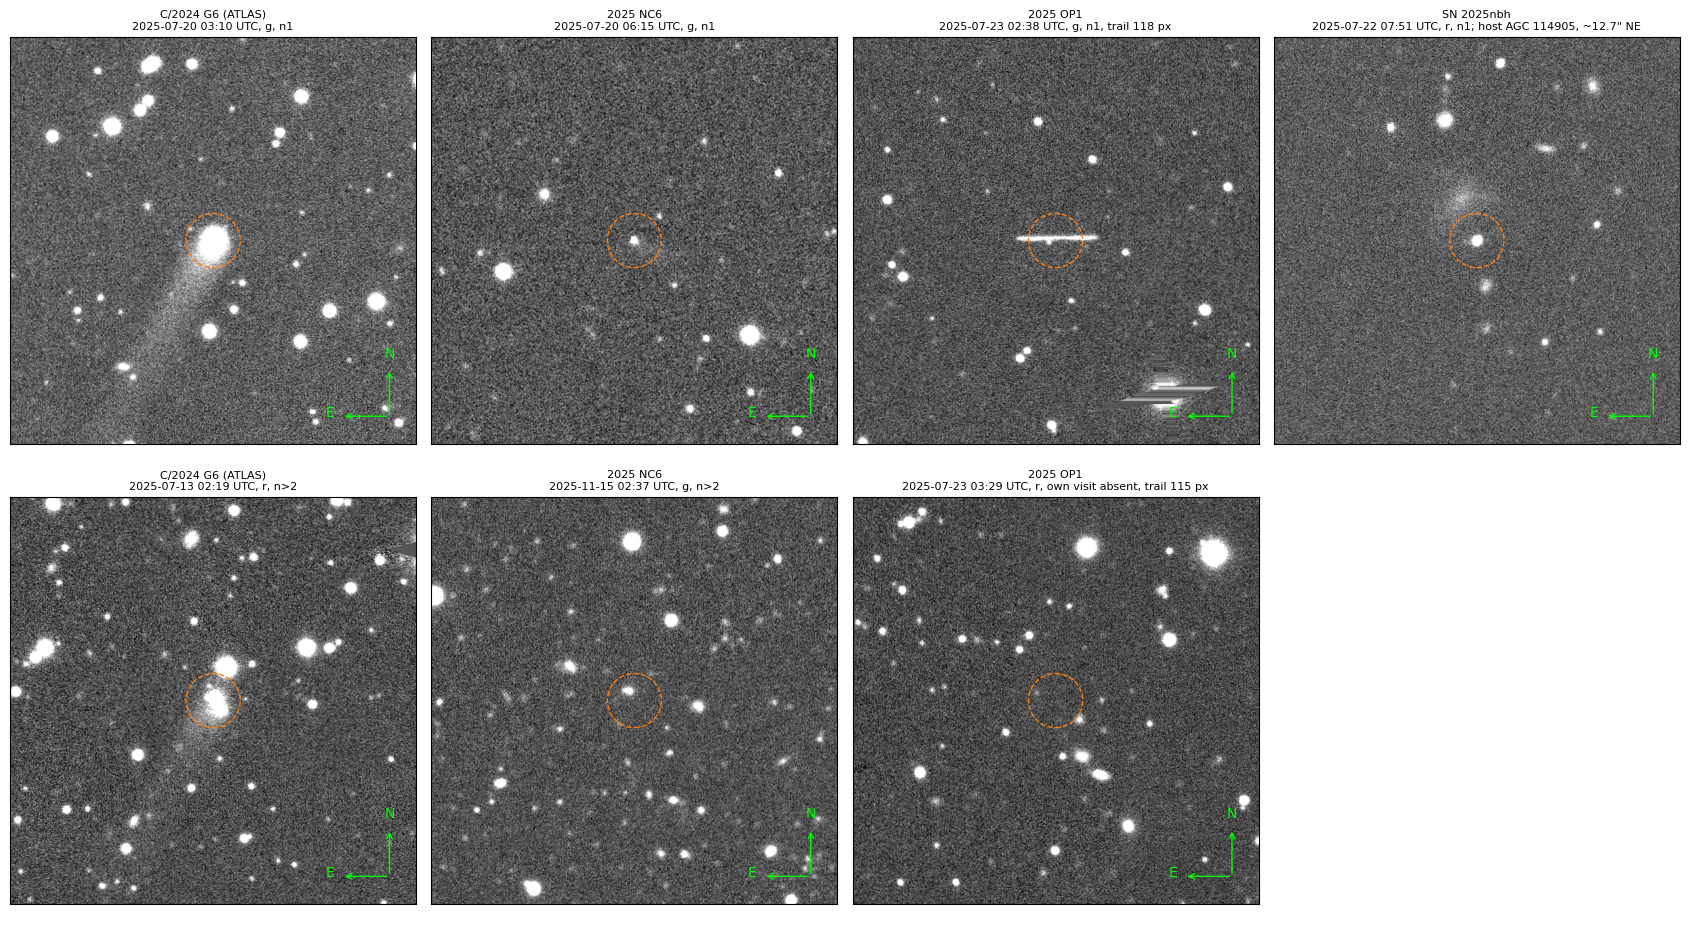

In [5]:
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.visualization import ImageNormalize, ZScaleInterval


@functools.lru_cache(maxsize=4)
def coadd_image(key):
    """Full patch image in nJy with an array-indexed FITS WCS."""
    entry = coadd(*key)
    image = butler.get(entry["ref"].makeComponentRef("image"))
    wcs = entry["projection"].as_fits_wcs(image.bbox)
    return np.asarray(image.array, dtype=np.float32) * image.unit.to(u.nJy), wcs


def north_up_cutout(key, ra, dec, size=CUTOUT_PIXELS):
    """Bilinear resampling onto a north-up, east-left 0.2"/px grid centred on (ra, dec)."""
    data, wcs = coadd_image(key)
    out = WCS(naxis=2)
    out.wcs.ctype, out.wcs.crval = ["RA---TAN", "DEC--TAN"], [ra, dec]
    out.wcs.crpix = [(size + 1) / 2] * 2
    out.wcs.cdelt = [-PIXEL_SCALE_ARCSEC / 3600, PIXEL_SCALE_ARCSEC / 3600]
    yy, xx = np.mgrid[0:size, 0:size]
    x, y = wcs.world_to_pixel(out.pixel_to_world(xx, yy))
    return map_coordinates(data, [y, x], order=1, cval=np.nan), out


def label(t):
    """Panel subtitle: time, band, status and any trail length."""
    trail = f", trail {t.trail_px:.0f} px" if t.trail_px > 5 else ""
    return f"{t.utc[:16]} UTC, {t.band}, {t.status}{trail}"


sn_top = sn.loc[SUPERNOVA["band"]]
sn_deep = sn[sn.n > 2].sort_values("n")
rows = [
    [(t.object, t.key, t.ra, t.dec, label(t)) for t in targets[targets.role == r].itertuples()]
    for r in ("letter", "contrast")
]
rows[0].append(
    (
        SUPERNOVA["name"],
        sn_top.key,
        SUPERNOVA["ra"],
        SUPERNOVA["dec"],
        f"{sn_top.first_utc} UTC, {SUPERNOVA['band']}, n1; host {SUPERNOVA['host_note']}",
    )
)
if len(sn_deep):  # the supernova's deepest band, if any band stacks more than two visits
    deep = sn_deep.iloc[-1]
    rows[1].append((SUPERNOVA["name"], deep.key, SUPERNOVA["ra"], SUPERNOVA["dec"],
                    f"{deep.name}, {deep.status} ({deep.n} visits)"))  # fmt: skip

fig, axes = plt.subplots(2, 4, figsize=(17, 9.6))
for ax in axes.flat:
    ax.set_axis_off()  # panels with an image are switched back on below
for r, row in enumerate(rows):
    for ax, (name, key, ra, dec, text) in zip(axes[r][: len(row)], row, strict=True):
        ax.set_axis_on()
        data, wcs = north_up_cutout(key, ra, dec)
        if r == 0:
            stem = name.replace("/", "_").replace(" ", "_").replace("(", "").replace(")", "")
            header = wcs.to_header()
            header.update(OBJECT=name, BUNIT="nJy", TRACT=key[0], PATCH=key[1], FILTER=key[2])
            hdu = fits.PrimaryHDU(data.astype(np.float32), header)
            hdu.writeto(PRODUCTS / f"{stem}_{key[2]}.fits", overwrite=True)
        finite = data[np.isfinite(data)]
        ax.imshow(data, origin="lower", cmap="gray",
                  norm=ImageNormalize(finite, interval=ZScaleInterval()))  # fmt: skip
        centre = ((CUTOUT_PIXELS - 1) / 2,) * 2
        ax.add_patch(plt.Circle(centre, 40, fill=False, color="tab:orange", ls="--"))
        ax.set_title(f"{name}\n{text}", fontsize=8)
        ax.set_xticks([]), ax.set_yticks([])
        origin = np.array([CUTOUT_PIXELS - 40, 40])  # compass: north up, east left
        for tip, letter_ in ((origin + [0, 70], "N"), (origin - [70, 0], "E")):
            ax.annotate("", xy=tip, xytext=origin, arrowprops=dict(arrowstyle="->", color="lime"))
            ax.text(*(tip + (origin - tip) * -0.25), letter_, color="lime", ha="center")
fig.tight_layout()
fig.savefig(PRODUCTS / "edp2_horizons_demo_gallery.png", dpi=150)
plt.show()

## Where to go next

* **Other objects and epochs.** Add rows to `VISITS_TO_CHECK` and `HORIZONS_IDS`. To find
  the visits in the first place you need a survey simulator: the companion notebook
  `edp2_tails_trails_rsp_demo.ipynb` installs Ponder and Sorcha and searches all DP2 visits.
* **The rest of the sky.** The full-catalog search, cutout mosaicking across patches, and
  the trailing and depth screens are in
  the Letter's analysis code (Rubin-eDP2-SolSys-Explorer, not yet public).
* **Credit.** Please acknowledge Rubin eDP2 data as described on
  [dp2.lsst.io](https://dp2.lsst.io), and JPL Horizons as described on its
  [site](https://ssd.jpl.nasa.gov/horizons/).